In [1]:
!pip install jupyterlab pandas pyarrow matplotlib seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import pandas as pd

# Locate the data folder from the notebook's working directory
DATA_DIR = Path("../data")

files = sorted(DATA_DIR.glob("*.parquet"))

print("Files found:", len(files))

if not files:
    raise FileNotFoundError(
        f"No Parquet files found in {DATA_DIR.resolve()}"
    )

# Load and combine all monthly files
df = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Files found: 12
Dataset loaded successfully!
Rows: 300378
Columns: 9


,service_date,a_stop,b_stop,a_station,b_station,route_ids,n_trips,mean_seconds,median_seconds
0,2025-01-01,101S,103S,Van Cortlandt Park-242 St,238 St,1,125,97.30,90.0
1,2025-01-01,103N,101N,238 St,Van Cortlandt Park-242 St,1,80,174.16,174.0
2,2025-01-01,103S,104S,238 St,231 St,1,125,87.01,90.0
3,2025-01-01,104N,101N,231 St,Van Cortlandt Park-242 St,1,38,214.93,210.0
4,2025-01-01,104N,103N,231 St,238 St,1,80,128.88,105.0


In [3]:
# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Data types and non-null counts
df.info()

# 3. Missing values
print("\nMissing values per column:")
display(df.isnull().sum().to_frame("missing_count"))

# 4. Duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# 5. Numerical summary
display(df.describe().T)

# 6. Date range
df["service_date"] = pd.to_datetime(df["service_date"])

print("\nStart date:", df["service_date"].min())
print("End date:", df["service_date"].max())

# 7. Check invalid numerical values
print("\nZero or negative trip counts:", (df["n_trips"] <= 0).sum())
print("Zero or negative mean times:", (df["mean_seconds"] <= 0).sum())
print("Zero or negative median times:", (df["median_seconds"] <= 0).sum())

Dataset shape: (300378, 9)
<class 'pandas.DataFrame'>
RangeIndex: 300378 entries, 0 to 300377
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   service_date    300378 non-null  object 
 1   a_stop          300378 non-null  str    
 2   b_stop          300378 non-null  str    
 3   a_station       298330 non-null  str    
 4   b_station       298254 non-null  str    
 5   route_ids       300378 non-null  str    
 6   n_trips         300378 non-null  int64  
 7   mean_seconds    300058 non-null  float64
 8   median_seconds  300378 non-null  float64
dtypes: float64(2), int64(1), object(1), str(5)
memory usage: 30.4+ MB

Missing values per column:


,missing_count
service_date,0
a_stop,0
b_stop,0
a_station,2048
b_station,2124
route_ids,0
n_trips,0
mean_seconds,320
median_seconds,0



Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
n_trips,300378.0,144.755748,75.493548,10.00,100.00,132.00,200.00,517.00
mean_seconds,300058.0,139.215867,90.070525,23.46,92.42,110.03,149.37,1236.62
median_seconds,300378.0,133.586433,88.673587,23.00,90.00,105.00,141.00,1257.00



Start date: 2025-01-01 00:00:00
End date: 2025-12-31 00:00:00

Zero or negative trip counts: 0
Zero or negative mean times: 0
Zero or negative median times: 0


In [5]:

# Missing values
print("MISSING VALUES")
display(
    df.isnull().sum()
      .to_frame("missing_count")
      .assign(
          missing_pct=lambda x:
          (x["missing_count"] / len(df) * 100).round(3)
      )
)

# Exact duplicates
print("\nExact duplicate rows:", df.duplicated().sum())

# Date coverage
df["service_date"] = pd.to_datetime(df["service_date"])

print("\nDate range:")
print(df["service_date"].min(), "to", df["service_date"].max())

print("\nUnique service dates:", df["service_date"].nunique())

# Invalid numerical values
print("\nNon-positive trip counts:", (df["n_trips"] <= 0).sum())
print("Non-positive mean times:",
      (df["mean_seconds"].dropna() <= 0).sum())
print("Non-positive median times:",
      (df["median_seconds"] <= 0).sum())

# Missing station-name examples
print("\nExamples with missing station names:")
display(
    df.loc[
        df["a_station"].isna() | df["b_station"].isna(),
        ["a_stop", "b_stop", "a_station", "b_station", "route_ids"]
    ].head(10)
)


MISSING VALUES


,missing_count,missing_pct
service_date,0,0.000
a_stop,0,0.000
b_stop,0,0.000
a_station,2048,0.682
b_station,2124,0.707
route_ids,0,0.000
n_trips,0,0.000
mean_seconds,320,0.107
median_seconds,0,0.000



Exact duplicate rows: 0

Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00

Unique service dates: 261

Non-positive trip counts: 0
Non-positive mean times: 0
Non-positive median times: 0

Examples with missing station names:


,a_stop,b_stop,a_station,b_station,route_ids
759,G21S,R60S,Queens Plaza,NaN,R
788,H04N,H19N,Broad Channel,NaN,H
808,H19S,H04S,NaN,Broad Channel,H
962,R09S,R60S,Queensboro Plaza,NaN,N
963,R11N,R60N,Lexington Av/59 St,NaN,N R
1001,R27S,R65S,Whitehall St-South Ferry,NaN,N R
1002,R28N,R65N,Court St,NaN,R
1043,R60N,G21N,NaN,Queens Plaza,R
1044,R60N,R09N,NaN,Queensboro Plaza,N
1045,R60S,R11S,NaN,Lexington Av/59 St,N R


In [6]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [7]:
df["service_date"] = pd.to_datetime(df["service_date"])

print("Start date:", df["service_date"].min())
print("End date:", df["service_date"].max())
print("Unique service dates:", df["service_date"].nunique())

Start date: 2025-01-01 00:00:00
End date: 2025-12-31 00:00:00
Unique service dates: 261


In [8]:
print("Non-positive trip counts:", (df["n_trips"] <= 0).sum())

print(
    "Non-positive mean travel times:",
    (df["mean_seconds"].dropna() <= 0).sum()
)

print(
    "Non-positive median travel times:",
    (df["median_seconds"] <= 0).sum()
)

Non-positive trip counts: 0
Non-positive mean travel times: 0
Non-positive median travel times: 0


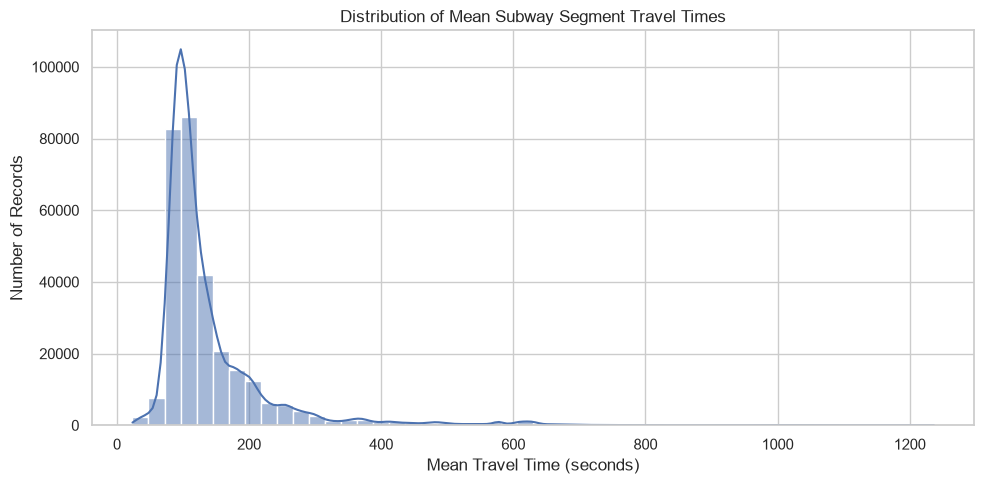

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="mean_seconds",
    bins=50,
    kde=True
)

plt.title("Distribution of Mean Subway Segment Travel Times")
plt.xlabel("Mean Travel Time (seconds)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [10]:
df["mean_seconds"].describe().round(2)

count    300058.00
mean        139.22
std          90.07
min          23.46
25%          92.42
50%         110.03
75%         149.37
max        1236.62
Name: mean_seconds, dtype: float64

In [11]:
df.nlargest(10, "mean_seconds")[
    [
        "service_date",
        "a_station",
        "b_station",
        "route_ids",
        "n_trips",
        "mean_seconds",
        "median_seconds"
    ]
]

,service_date,a_station,b_station,route_ids,n_trips,mean_seconds,median_seconds
52775,2025-03-05,St George,Great Kills,SS,17,1236.62,1257.0
68595,2025-03-26,E 180 St,3 Av-149 St,5,24,1179.76,1141.5
261361,2025-11-13,St George,Great Kills,SS,19,1166.53,1186.0
270500,2025-11-25,St George,Great Kills,SS,14,1161.44,1133.5
82338,2025-04-10,St George,Great Kills,SS,16,1156.23,1051.0
257938,2025-11-10,St George,Great Kills,SS,18,1135.29,1111.0
211715,2025-09-15,St George,Great Kills,SS,19,1129.67,1134.0
252207,2025-11-03,St George,Great Kills,SS,19,1115.93,1051.0
189827,2025-08-19,St George,Great Kills,SS,19,1112.13,1110.0
259075,2025-11-11,St George,Great Kills,SS,18,1105.93,1088.5


In [12]:
sg_gk = df[
    (df["a_station"] == "St George") &
    (df["b_station"] == "Great Kills")
]

print("Number of records:", len(sg_gk))
print("Total trips represented:", sg_gk["n_trips"].sum())
print("Mean travel time (seconds):", round(sg_gk["mean_seconds"].mean(), 2))
print("Median of daily mean times (seconds):", round(sg_gk["mean_seconds"].median(), 2))
print("Minimum mean time (seconds):", round(sg_gk["mean_seconds"].min(), 2))
print("Maximum mean time (seconds):", round(sg_gk["mean_seconds"].max(), 2))

Number of records: 253
Total trips represented: 4735
Mean travel time (seconds): 1012.07
Median of daily mean times (seconds): 1010.29
Minimum mean time (seconds): 908.0
Maximum mean time (seconds): 1236.62


In [13]:
# Convert seconds to minutes for easier interpretation
df["mean_minutes"] = df["mean_seconds"] / 60
df["median_minutes"] = df["median_seconds"] / 60

print("Overall median segment travel time (minutes):",
      round(df["mean_minutes"].median(), 2))

print("Overall mean segment travel time (minutes):",
      round(df["mean_minutes"].mean(), 2))

print("\nSt George → Great Kills average (minutes):",
      round(sg_gk["mean_seconds"].mean() / 60, 2))

Overall median segment travel time (minutes): 1.83
Overall mean segment travel time (minutes): 2.32

St George → Great Kills average (minutes): 16.87


In [14]:
route_analysis = (
    df.groupby("route_ids")
    .agg(
        avg_travel_minutes=("mean_minutes", "mean"),
        median_travel_minutes=("mean_minutes", "median"),
        total_trips=("n_trips", "sum"),
        records=("route_ids", "size")
    )
    .sort_values("avg_travel_minutes", ascending=False)
)

display(route_analysis.round(2))

,avg_travel_minutes,median_travel_minutes,total_trips,records
route_ids,,,,
SS,16.87,16.84,4735,253
A B D E,7.99,7.99,234,1
A D,7.56,8.02,59257,265
6X,7.05,6.97,23985,588
D F N Q R,6.76,6.84,949,5
...,...,...,...,...
B D F FX R,1.43,1.43,694,2
F Q,1.37,1.63,26377,195
GS,1.25,1.28,110559,520


In [15]:
route_reliable = route_analysis[route_analysis["records"] >= 100].copy()

print("Route labels before filtering:", len(route_analysis))
print("Route labels with at least 100 records:", len(route_reliable))

display(
    route_reliable
    .sort_values("avg_travel_minutes", ascending=False)
    .head(15)
    .round(2)
)

Route labels before filtering: 356
Route labels with at least 100 records: 115


,avg_travel_minutes,median_travel_minutes,total_trips,records
route_ids,,,,
SS,16.87,16.84,4735,253
A D,7.56,8.02,59257,265
6X,7.05,6.97,23985,588
A B D,6.42,7.53,32845,141
J M Z,6.30,6.45,116160,561
7X,5.10,4.69,22633,833
N,4.74,3.50,193233,2079
D N Q,4.37,4.66,24896,166
A C D,4.20,2.38,38471,178


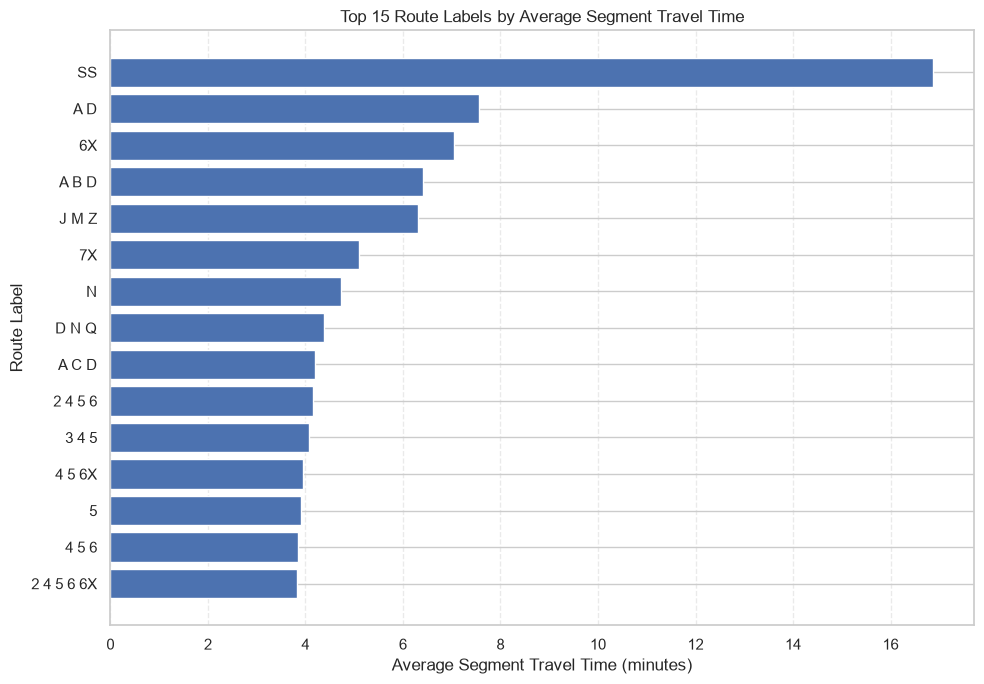

In [16]:
import matplotlib.pyplot as plt

top_routes = (
    route_reliable
    .sort_values("avg_travel_minutes", ascending=False)
    .head(15)
    .sort_values("avg_travel_minutes")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_routes.index,
    top_routes["avg_travel_minutes"]
)

plt.title("Top 15 Route Labels by Average Segment Travel Time")
plt.xlabel("Average Segment Travel Time (minutes)")
plt.ylabel("Route Label")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [17]:
segment_analysis = (
    df.groupby(["a_station", "b_station", "route_ids"])
    .agg(
        avg_travel_minutes=("mean_minutes", "mean"),
        median_travel_minutes=("mean_minutes", "median"),
        total_trips=("n_trips", "sum"),
        records=("service_date", "count")
    )
    .query("records >= 100")
    .sort_values("avg_travel_minutes", ascending=False)
)

display(segment_analysis.head(15).round(2))

avg_travel_minutes  \
a_station                b_station                          route_ids                       
St George                Great Kills                        SS                      16.87   
3 Av-149 St              E 180 St                           5                       11.78   
E 180 St                 3 Av-149 St                        5                       11.43   
Canal St                 Atlantic Av-Barclays Ctr           N                       11.04   
75 St-Elderts Ln         Sutphin Blvd-Archer Av-JFK Airport J                       10.49   
Woodhaven Blvd           Van Siclen Av                      J Z                     10.46   
Atlantic Av-Barclays Ctr Canal St                           N                       10.31   
Woodhaven Blvd           Crescent St                        J                       10.25   
                         Norwood Av                         J                       10.24   
                         Cleveland St                       J                       10.22   
Grand St                 Atlantic Av-Barclays Ctr           D                       10.16   
Woodhaven Blvd           85 St-Forest Pkwy                  J Z                      9.64   
75 St-Elderts Ln         85 St-Forest Pkwy                  J                        9.61   
Woodhaven Blvd           85 St-Forest Pkwy                  J                        9.61   
Atlantic Av-Barclays Ctr Grand St                           D                        9.47   

                                                                       median_travel_minutes  \
a_station                b_station                          route_ids                          
St George                Great Kills                        SS                         16.84   
3 Av-149 St              E 180 St                           5                          11.61   
E 180 St                 3 Av-149 St                        5                          11.03   
Canal St                 Atlantic Av-Barclays Ctr           N                          11.02   
75 St-Elderts Ln         Sutphin Blvd-Archer Av-JFK Airport J                          10.49   
Woodhaven Blvd           Van Siclen Av                      J Z                        10.47   
Atlantic Av-Barclays Ctr Canal St                           N                          10.25   
Woodhaven Blvd           Crescent St                        J                          10.24   
                         Norwood Av                         J                          10.22   
                         Cleveland St                       J                          10.23   
Grand St                 Atlantic Av-Barclays Ctr           D                          10.11   
Woodhaven Blvd           85 St-Forest Pkwy                  J Z                         9.64   
75 St-Elderts Ln         85 St-Forest Pkwy                  J                           9.62   
Woodhaven Blvd           85 St-Forest Pkwy                  J                           9.62   
Atlantic Av-Barclays Ctr Grand St                           D                           9.45   

                                                                       total_trips  \
a_station                b_station                          route_ids                
St George                Great Kills                        SS                4735   
3 Av-149 St              E 180 St                           5                 7443   
E 180 St                 3 Av-149 St                        5                 7149   
Canal St                 Atlantic Av-Barclays Ctr           N                24492   
75 St-Elderts Ln         Sutphin Blvd-Archer Av-JFK Airport J                 4560   
Woodhaven Blvd           Van Siclen Av                      J Z               2971   
Atlantic Av-Barclays Ctr Canal St                           N                22057   
Woodhaven Blvd           Crescent St                        J                 3206

In [18]:
segment_variability = (
    df.groupby(["a_station", "b_station", "route_ids"])
    .agg(
        avg_minutes=("mean_minutes", "mean"),
        std_minutes=("mean_minutes", "std"),
        median_minutes=("mean_minutes", "median"),
        records=("service_date", "count"),
        total_trips=("n_trips", "sum")
    )
    .query("records >= 100")
)

segment_variability["cv_percent"] = (
    segment_variability["std_minutes"]
    / segment_variability["avg_minutes"]
) * 100

display(
    segment_variability
    .sort_values("cv_percent", ascending=False)
    .head(15)
    .round(2)
)

,,,avg_minutes,std_minutes,median_minutes,records,total_trips,cv_percent
a_station,b_station,route_ids,,,,,,
Botanic Garden,Prospect Park,FS,2.12,1.24,2.09,110,2525,58.40
Shepherd Av,Euclid Av,A C,0.99,0.44,0.87,260,7801,44.99
Avenue U,Kings Hwy,F,2.11,0.83,1.93,107,10918,39.12
Crescent St,Cypress Hills,J Z,3.93,1.43,3.66,113,12851,36.50
Parsons Blvd,169 St,F,3.10,1.11,2.72,105,13965,35.82
20 Av,Bay Pkwy,D,1.42,0.49,1.28,168,15910,34.74
Aqueduct-N Conduit Av,Howard Beach-JFK Airport,A,1.84,0.60,2.18,257,15603,32.72
86 St,Bay Ridge-95 St,R,0.62,0.19,0.56,251,6105,31.17
Junction Blvd,103 St-Corona Plaza,7,1.03,0.31,0.82,235,37559,30.53


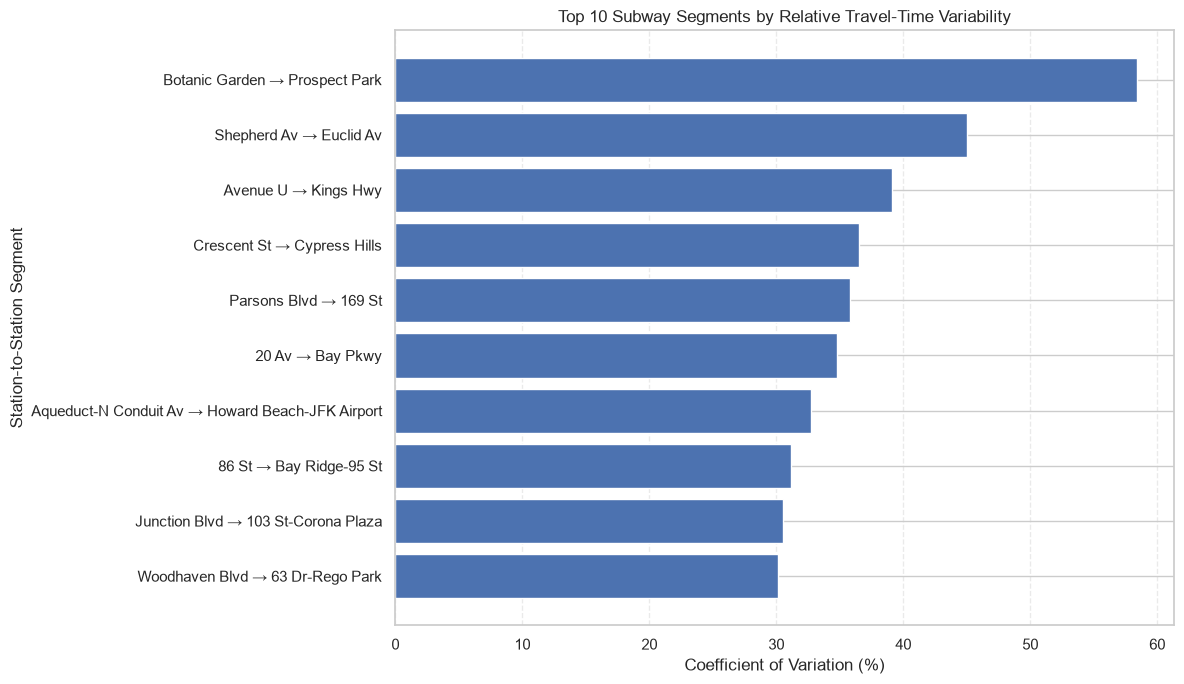

In [19]:
import matplotlib.pyplot as plt

top_variable = (
    segment_variability
    .sort_values("cv_percent", ascending=False)
    .head(10)
    .copy()
)

top_variable["segment"] = (
    top_variable.index.get_level_values("a_station")
    + " → "
    + top_variable.index.get_level_values("b_station")
)

top_variable = top_variable.sort_values("cv_percent")

plt.figure(figsize=(12, 7))

plt.barh(
    top_variable["segment"],
    top_variable["cv_percent"]
)

plt.title("Top 10 Subway Segments by Relative Travel-Time Variability")
plt.xlabel("Coefficient of Variation (%)")
plt.ylabel("Station-to-Station Segment")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [20]:
# Extract date-based features
df["service_date"] = pd.to_datetime(df["service_date"])

df["day_of_week"] = df["service_date"].dt.day_name()
df["day_number"] = df["service_date"].dt.dayofweek

# Compare travel times across weekdays
weekday_analysis = (
    df.groupby(["day_number", "day_of_week"])
    .agg(
        avg_travel_minutes=("mean_minutes", "mean"),
        median_travel_minutes=("mean_minutes", "median"),
        total_trips=("n_trips", "sum"),
        records=("mean_minutes", "count")
    )
    .sort_index()
)

display(weekday_analysis.round(2))

C:\Users\Pradeep\AppData\Local\Temp\ipykernel_18932\2282396671.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_number"] = df["service_date"].dt.dayofweek


,,avg_travel_minutes,median_travel_minutes,total_trips,records
day_number,day_of_week,,,,
0,Monday,2.30,1.82,8601900,59516
1,Tuesday,2.33,1.84,8759632,59995
2,Wednesday,2.33,1.84,8941132,61042
3,Thursday,2.33,1.84,8553287,59784
4,Friday,2.31,1.83,8625491,59721


In [21]:
# Count service dates by weekday
date_coverage = (
    df[["service_date", "day_of_week", "day_number"]]
    .drop_duplicates(subset=["service_date"])
    .groupby(["day_number", "day_of_week"])
    .agg(
        service_days=("service_date", "nunique"),
        first_date=("service_date", "min"),
        last_date=("service_date", "max")
    )
    .sort_index()
)

display(date_coverage)

,,service_days,first_date,last_date
day_number,day_of_week,,,
0,Monday,52,2025-01-06,2025-12-29
1,Tuesday,52,2025-01-07,2025-12-30
2,Wednesday,53,2025-01-01,2025-12-31
3,Thursday,52,2025-01-02,2025-12-25
4,Friday,52,2025-01-03,2025-12-26


In [22]:
monthly_analysis = (
    df.groupby(df["service_date"].dt.to_period("M"))
    .agg(
        avg_travel_minutes=("mean_minutes", "mean"),
        median_travel_minutes=("mean_minutes", "median"),
        total_trips=("n_trips", "sum"),
        records=("mean_minutes", "count")
    )
)

monthly_analysis.index = monthly_analysis.index.astype(str)

display(monthly_analysis.round(2))

,avg_travel_minutes,median_travel_minutes,total_trips,records
service_date,,,,
2025-01,2.32,1.83,3865701,26408
2025-02,2.31,1.82,3279073,22823
2025-03,2.28,1.82,2597551,23695
2025-04,2.33,1.85,3834455,25374
2025-05,2.32,1.84,3772079,25286
2025-06,2.36,1.85,3639156,24399
2025-07,2.34,1.84,3865278,26505
2025-08,2.32,1.82,3625461,24359
2025-09,2.31,1.83,3748665,25340


Chart saved to: ..\visuals\monthly_travel_time_trends.png


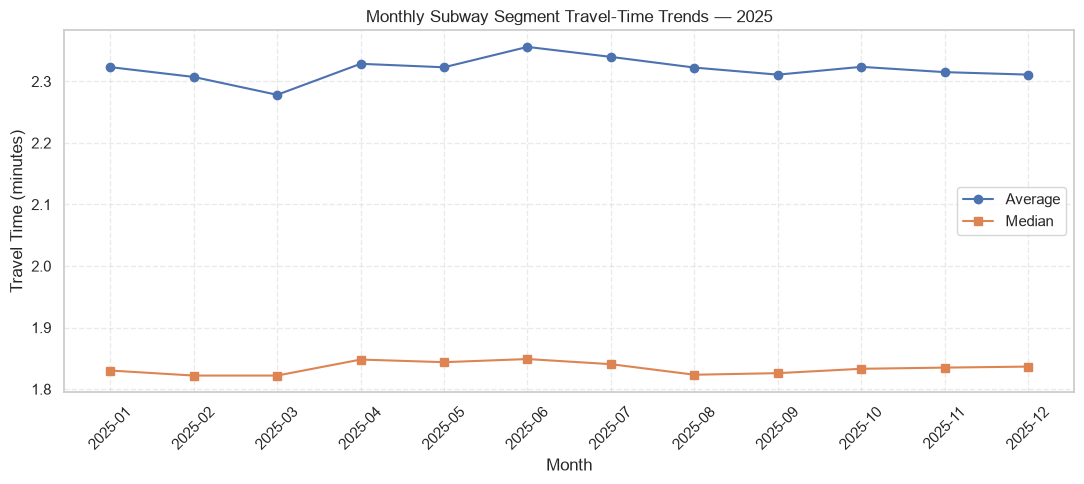

In [23]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create visuals folder in the project root
VISUALS_DIR = Path("../visuals")
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_analysis.index,
    monthly_analysis["avg_travel_minutes"],
    marker="o",
    label="Average"
)

plt.plot(
    monthly_analysis.index,
    monthly_analysis["median_travel_minutes"],
    marker="s",
    label="Median"
)

plt.title("Monthly Subway Segment Travel-Time Trends — 2025")
plt.xlabel("Month")
plt.ylabel("Travel Time (minutes)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

# Save high-resolution image
output_path = VISUALS_DIR / "monthly_travel_time_trends.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Chart saved to: {output_path}")

plt.show()

In [24]:
monthly_coverage = (
    df.groupby(df["service_date"].dt.to_period("M"))
    .agg(
        service_days=("service_date", "nunique"),
        segment_records=("mean_minutes", "count"),
        total_trips=("n_trips", "sum")
    )
)

monthly_coverage.index = monthly_coverage.index.astype(str)

display(monthly_coverage)

,service_days,segment_records,total_trips
service_date,,,
2025-01,23,26408,3865701
2025-02,20,22823,3279073
2025-03,21,23695,2597551
2025-04,22,25374,3834455
2025-05,22,25286,3772079
2025-06,21,24399,3639156
2025-07,23,26505,3865278
2025-08,21,24359,3625461
2025-09,22,25340,3748665


In [25]:
# Count how many distinct months each segment appears in
segment_month_coverage = (
    df.assign(month=df["service_date"].dt.to_period("M"))
    .groupby(["a_station", "b_station", "route_ids"])
    .agg(
        months_present=("month", "nunique"),
        records=("service_date", "count"),
        avg_travel_minutes=("mean_minutes", "mean")
    )
)

print("Total unique station-route segments:", len(segment_month_coverage))
print("\nSegments appearing in all 12 months:")
print((segment_month_coverage["months_present"] == 12).sum())

print("\nSegment coverage distribution:")
display(segment_month_coverage["months_present"].value_counts().sort_index())

Total unique station-route segments: 5280

Segments appearing in all 12 months:
1312

Segment coverage distribution:


months_present
1     1401
2      478
3      294
4      244
5      251
6      298
7      294
8      251
9      125
10     146
11     186
12    1312
Name: count, dtype: int64

In [26]:
# Prepare the initial ML dataset
ml_df = df.copy()

# Keep rows with a valid target and essential categorical features
ml_df = ml_df.dropna(
    subset=[
        "mean_seconds",
        "a_station",
        "b_station",
        "route_ids",
        "service_date"
    ]
).copy()

# Create calendar features
ml_df["day_of_week"] = ml_df["service_date"].dt.dayofweek
ml_df["month"] = ml_df["service_date"].dt.month
ml_df["day_of_month"] = ml_df["service_date"].dt.day

# Select features and target
features = [
    "a_station",
    "b_station",
    "route_ids",
    "day_of_week",
    "month",
    "day_of_month"
]

target = "mean_seconds"

print("ML dataset shape:", ml_df.shape)
print("Features:", features)
print("Target:", target)
print("Missing target values:", ml_df[target].isna().sum())

display(ml_df[features + [target]].head())

ML dataset shape: (296114, 15)
Features: ['a_station', 'b_station', 'route_ids', 'day_of_week', 'month', 'day_of_month']
Target: mean_seconds
Missing target values: 0


C:\Users\Pradeep\AppData\Local\Temp\ipykernel_18932\307079681.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ml_df["day_of_week"] = ml_df["service_date"].dt.dayofweek


,a_station,b_station,route_ids,day_of_week,month,day_of_month,mean_seconds
0,Van Cortlandt Park-242 St,238 St,1,2,1,1,97.30
1,238 St,Van Cortlandt Park-242 St,1,2,1,1,174.16
2,238 St,231 St,1,2,1,1,87.01
3,231 St,Van Cortlandt Park-242 St,1,2,1,1,214.93
4,231 St,238 St,1,2,1,1,128.88


In [27]:
print("Dataset shape:", ml_df.shape)

print("\nMissing values:")
display(ml_df[features + [target]].isna().sum())

print("\nTarget variable statistics (seconds):")
display(ml_df[target].describe().round(2))

print("\nNon-positive target values:", (ml_df[target] <= 0).sum())

print("\nUnique station pairs:", 
      ml_df[["a_station", "b_station"]].drop_duplicates().shape[0])

print("\nDate range:")
print(ml_df["service_date"].min(), "to", ml_df["service_date"].max())

Dataset shape: (296114, 15)

Missing values:


a_station       0
b_station       0
route_ids       0
day_of_week     0
month           0
day_of_month    0
mean_seconds    0
dtype: int64


Target variable statistics (seconds):


count    296114.00
mean        139.19
std          90.38
min          23.46
25%          92.40
50%         109.82
75%         148.73
max        1236.62
Name: mean_seconds, dtype: float64


Non-positive target values: 0

Unique station pairs: 1371

Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00


In [28]:
from pathlib import Path

# Save the processed dataset in the project's data folder
DATA_DIR = Path("../data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

output_file = DATA_DIR / "subway_ml_dataset.parquet"

# Save only the features, target, and date needed for modeling
ml_columns = [
    "service_date",
    "a_station",
    "b_station",
    "route_ids",
    "day_of_week",
    "month",
    "day_of_month",
    "mean_seconds"
]

ml_df[ml_columns].to_parquet(output_file, index=False)

print("ML dataset saved successfully!")
print("File:", output_file.resolve())
print("Rows:", len(ml_df))
print("Columns:", len(ml_columns))
print("File size (MB):", round(output_file.stat().st_size / (1024 ** 2), 2))

ML dataset saved successfully!
File: C:\Users\Pradeep\OneDrive\Desktop\projects\NYC-Subway-Analytics\data\subway_ml_dataset.parquet
Rows: 296114
Columns: 8
File size (MB): 1.3


In [29]:
from pathlib import Path

DATA_DIR = Path("../data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

output_file = DATA_DIR / "subway_ml_dataset.parquet"

ml_columns = [
    "service_date",
    "a_station",
    "b_station",
    "route_ids",
    "day_of_week",
    "month",
    "day_of_month",
    "mean_seconds"
]

ml_df[ml_columns].to_parquet(output_file, index=False)

print("ML dataset saved successfully!")
print("File:", output_file.resolve())
print("Rows:", len(ml_df))
print("Columns:", len(ml_columns))
print("File size (MB):", round(output_file.stat().st_size / (1024 ** 2), 2))

ML dataset saved successfully!
File: C:\Users\Pradeep\OneDrive\Desktop\projects\NYC-Subway-Analytics\data\subway_ml_dataset.parquet
Rows: 296114
Columns: 8
File size (MB): 1.3


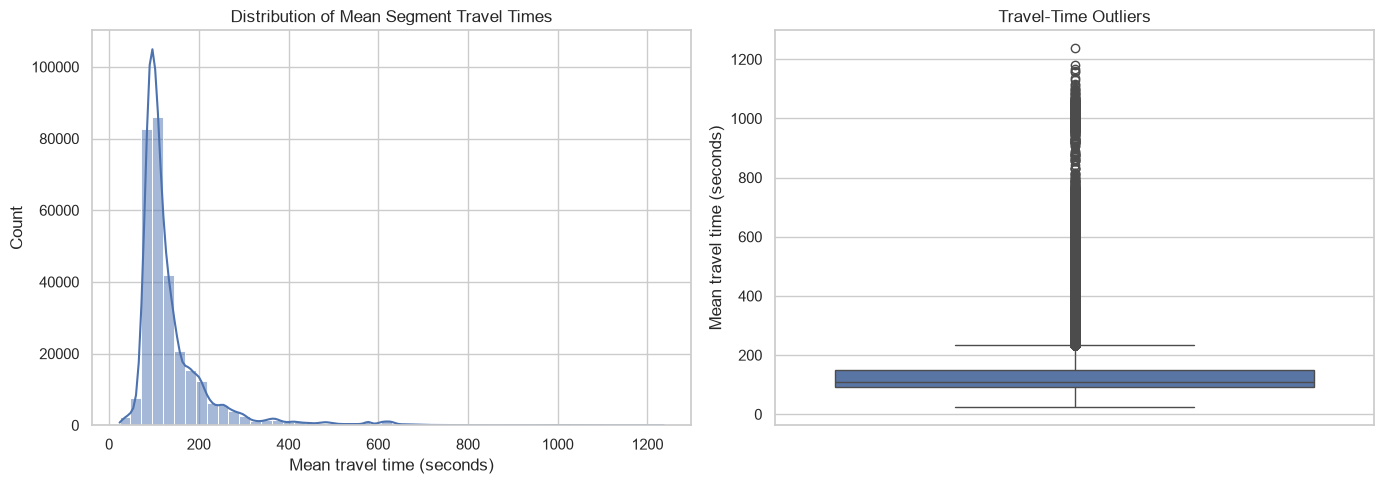

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="mean_seconds",
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Mean Segment Travel Times")
axes[0].set_xlabel("Mean travel time (seconds)")

sns.boxplot(
    data=df,
    y="mean_seconds",
    ax=axes[1]
)
axes[1].set_title("Travel-Time Outliers")
axes[1].set_ylabel("Mean travel time (seconds)")

plt.tight_layout()
plt.show()